<a href="https://colab.research.google.com/github/darsanipriya-13/sms_shield_ai/blob/main/Copy_of_spam__detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import re
import zipfile
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
import pickle

np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow version: 2.21.0
Libraries imported successfully!


In [ ]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip"

urllib.request.urlretrieve(url, "sms_dataset.zip")

with zipfile.ZipFile("sms_dataset.zip", "r") as zip_ref:
    zip_ref.extractall("sms_data")

df = pd.read_csv(
    "sms_data/SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"],
    encoding="utf-8"
)

print("Original dataset shape:", df.shape)
print(df.head())
print("\nClass distribution:")
print(df["label"].value_counts())

Original dataset shape: (5572, 2)
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...

Class distribution:
label
ham     4825
spam     747
Name: count, dtype: int64


In [ ]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip"

urllib.request.urlretrieve(url, "sms_dataset.zip")

with zipfile.ZipFile("sms_dataset.zip", "r") as zip_ref:
    zip_ref.extractall("sms_data")

df = pd.read_csv(
    "sms_data/SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"],
    encoding="utf-8"
)

print("Original dataset shape:", df.shape)
print(df.head())
print("\nClass distribution:")
print(df["label"].value_counts())

Original dataset shape: (5572, 2)
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...

Class distribution:
label
ham     4825
spam     747
Name: count, dtype: int64


Selected dataset shape: (2000, 4)
label
ham     1751
spam     249
Name: count, dtype: int64


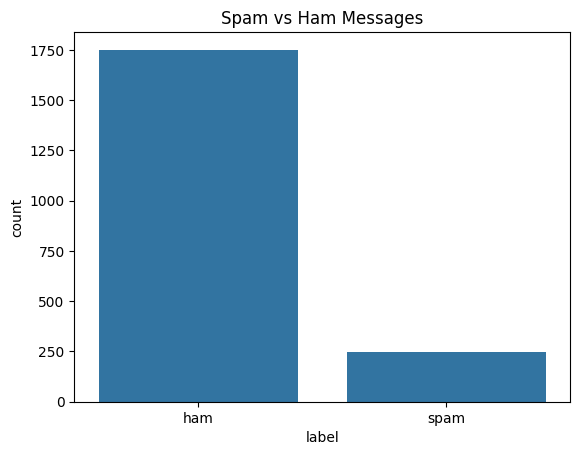

In [ ]:
# Remove rows with missing labels or messages
df = df.dropna(subset=["label", "message"])

# Remove empty messages and duplicate rows
df["message"] = df["message"].astype(str).str.strip()
df = df[df["message"] != ""]
df = df.drop_duplicates(subset=["label", "message"])

# Select approximately 2,000 total messages while preserving class proportions
target_total = 2000
if len(df) > target_total:
    sampling_fraction = target_total / len(df)
    # group_keys=True preserves the grouping column in the index, which we reset and clean up
    df = df.groupby("label", group_keys=True).apply(
        lambda x: x.sample(frac=sampling_fraction, random_state=42)
    ).reset_index(drop=True)

print("Selected dataset shape:", df.shape)
print(df["label"].value_counts())

sns.countplot(data=df, x="label")
plt.title("Spam vs Ham Messages")
plt.show()

In [ ]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_message"] = df["message"].apply(clean_text)

# Convert ham to 0 and spam to 1
df["label_id"] = df["label"].map({
    "ham": 0,
    "spam": 1
})

print(df[["message", "clean_message", "label", "label_id"]].head())
print("Missing values:\n", df.isnull().sum())

                                             message  \
0                   Sorry, I can't help you on this.   
1  How's my loverboy doing ? What does he do that...   
2  Sitting in mu waiting for everyone to get out ...   
3  Sure! I am driving but will reach my destinati...   
4               Sorry, went to bed early, nightnight   

                                       clean_message label  label_id  
0                     sorry i can t help you on this   ham         0  
1  how s my loverboy doing what does he do that k...   ham         0  
2  sitting in mu waiting for everyone to get out ...   ham         0  
3  sure i am driving but will reach my destinatio...   ham         0  
4                 sorry went to bed early nightnight   ham         0  
Missing values:
 label            0
message          0
clean_message    0
label_id         0
dtype: int64


In [ ]:
X = df["clean_message"].values
y = df["label_id"].values

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))

Training messages: 1600
Testing messages: 400


In [ ]:
MAX_WORDS = 5000
MAX_LEN = 100

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train)

train_sequences = tokenizer.texts_to_sequences(X_train)
test_sequences = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(
    train_sequences,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    test_sequences,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

print("Training sequence shape:", X_train_pad.shape)
print("Testing sequence shape:", X_test_pad.shape)
print("Example numerical sequence:", X_train_pad[0][:20])

Training sequence shape: (1600, 100)
Testing sequence shape: (400, 100)
Example numerical sequence: [ 303   24  903  904   35   25    5  304 1171 1171   28  435  205   57
  285    2  213  758   24  436]


In [ ]:
model = Sequential([
    Embedding(
        input_dim=MAX_WORDS,
        output_dim=64,
        mask_zero=True
    ),
    LSTM(64),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train_pad,
    y_train,
    epochs=15,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.8586 - loss: 0.5033 - val_accuracy: 0.8656 - val_loss: 0.2984
Epoch 2/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9609 - loss: 0.1352 - val_accuracy: 0.9688 - val_loss: 0.1167
Epoch 3/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9922 - loss: 0.0369 - val_accuracy: 0.9812 - val_loss: 0.0863
Epoch 4/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9977 - loss: 0.0181 - val_accuracy: 0.9844 - val_loss: 0.0874
Epoch 5/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9992 - loss: 0.0061 - val_accuracy: 0.9781 - val_loss: 0.1121
Epoch 6/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 1.0000 - loss: 0.0026 - val_accuracy: 0.9781 - val_loss: 0.1464


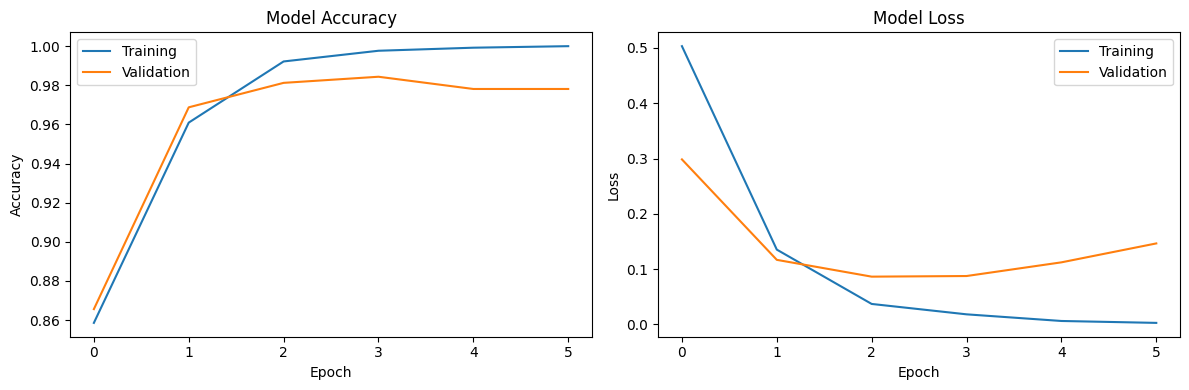

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
test_probabilities = model.predict(X_test_pad).ravel()

# Classify probabilities >= 0.5 as spam
y_pred = (test_probabilities >= 0.5).astype(int)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print(f"Accuracy:  {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nDetailed Classification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Ham", "Spam"],
        zero_division=0
    )
)

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
Accuracy:  0.9925 (99.25%)
Precision: 0.9796
Recall:    0.9600
F1-score:  0.9697

Detailed Classification Report:
              precision    recall  f1-score   support

         Ham       0.99      1.00      1.00       350
        Spam       0.98      0.96      0.97        50

    accuracy                           0.99       400
   macro avg       0.99      0.98      0.98       400
weighted avg       0.99      0.99      0.99       400



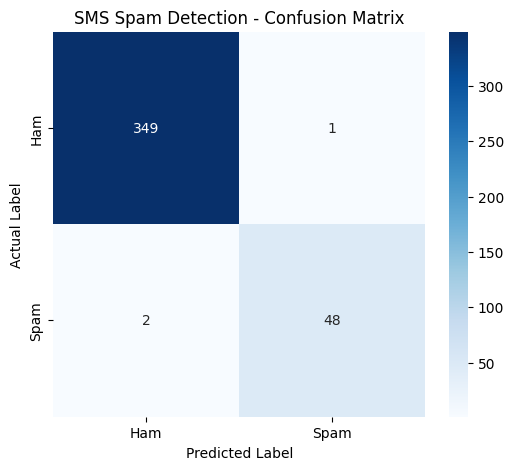

Confusion Matrix:
[[349   1]
 [  2  48]]


In [ ]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("SMS Spam Detection - Confusion Matrix")
plt.show()

print("Confusion Matrix:")
print(cm)

In [ ]:
def predict_sms(message):
    cleaned = clean_text(message)

    sequence = tokenizer.texts_to_sequences([cleaned])

    padded = pad_sequences(
        sequence,
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )

    probability = float(model.predict(padded, verbose=0)[0][0])

    if probability >= 0.5:
        label = "SPAM"
        confidence = probability
    else:
        label = "NOT SPAM (HAM)"
        confidence = 1 - probability

    return label, confidence

test_messages = [
    "Congratulations! You have won a free prize. Call now!",
    "Hi, are we meeting at college tomorrow?",
    "URGENT! Claim your cash reward by clicking the link",
    "Please send me the class notes when you are free"
]

for message in test_messages:
    label, confidence = predict_sms(message)
    print("Message:", message)
    print("Prediction:", label)
    print(f"Confidence: {confidence * 100:.2f}%")
    print("-" * 60)

Message: Congratulations! You have won a free prize. Call now!
Prediction: SPAM
Confidence: 93.39%
------------------------------------------------------------
Message: Hi, are we meeting at college tomorrow?
Prediction: NOT SPAM (HAM)
Confidence: 99.89%
------------------------------------------------------------
Message: URGENT! Claim your cash reward by clicking the link
Prediction: SPAM
Confidence: 92.75%
------------------------------------------------------------
Message: Please send me the class notes when you are free
Prediction: NOT SPAM (HAM)
Confidence: 99.87%
------------------------------------------------------------


In [ ]:
model.save("spam_lstm_model.keras")

with open("tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

print("Model and tokenizer saved successfully!")

Model and tokenizer saved successfully!


In [ ]:
import os

model_exists = os.path.exists("spam_lstm_model.keras")
tokenizer_exists = os.path.exists("tokenizer.pkl")

print(f"'spam_lstm_model.keras' exists: {model_exists}")
print(f"'tokenizer.pkl' exists: {tokenizer_exists}")
print("\nFiles in current directory:", os.listdir("."))

'spam_lstm_model.keras' exists: False
'tokenizer.pkl' exists: False

Files in current directory: ['.config', 'sms_dataset.zip', 'sms_data', 'sample_data']


Dataset successfully recreated!
Selected dataset shape: (2000, 2)
label
ham     1751
spam     249
Name: count, dtype: int64


/tmp/ipykernel_1278/2995005441.py:35: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df = df.groupby("label", group_keys=True).apply(


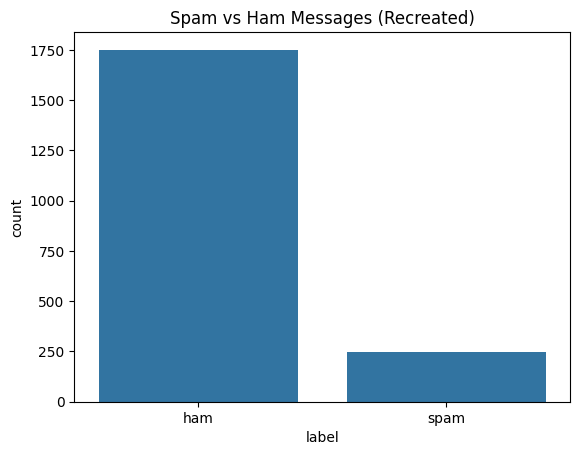

In [ ]:
import urllib.request
import zipfile
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Download and unzip the SMS Spam collection
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip"
urllib.request.urlretrieve(url, "sms_dataset.zip")

with zipfile.ZipFile("sms_dataset.zip", "r") as zip_ref:
    zip_ref.extractall("sms_data")

# 2. Load the dataset into a DataFrame
df = pd.read_csv(
    "sms_data/SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"],
    encoding="utf-8"
)

# 3. Clean and Preprocess
df = df.dropna(subset=["label", "message"])
df["message"] = df["message"].astype(str).str.strip()
df = df[df["message"] != ""]
df = df.drop_duplicates(subset=["label", "message"])

# 4. Sample down to ~2,000 total messages preserving class balance
target_total = 2000
if len(df) > target_total:
    sampling_fraction = target_total / len(df)
    # To avoid the deprecation warning while retaining the 'label' column,
    # we can group by 'label' and sample while explicitly preserving the structure.
    df = df.groupby("label", group_keys=True).apply(
        lambda x: x.sample(frac=sampling_fraction, random_state=42)
    ).reset_index(drop=True)

print("Dataset successfully recreated!")
print("Selected dataset shape:", df.shape)
print(df["label"].value_counts())

sns.countplot(data=df, x="label")
plt.title("Spam vs Ham Messages (Recreated)")
plt.show()

In [ ]:
import re
import pickle
import numpy as np
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# 1. Clean Text
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_message"] = df["message"].apply(clean_text)
df["label_id"] = df["label"].map({"ham": 0, "spam": 1})

# 2. Train/Test Split
X = df["clean_message"].values
y = df["label_id"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 3. Tokenization & Padding
MAX_WORDS = 5000
MAX_LEN = 100

tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

X_train_pad = pad_sequences(tokenizer.texts_to_sequences(X_train), maxlen=MAX_LEN, padding="post", truncating="post")
X_test_pad = pad_sequences(tokenizer.texts_to_sequences(X_test), maxlen=MAX_LEN, padding="post", truncating="post")

# 4. Define LSTM Model
model = Sequential([
    Embedding(input_dim=MAX_WORDS, output_dim=64, mask_zero=True),
    LSTM(64),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dense(1, activation="sigmoid")
])

model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

# 5. Train Model
early_stop = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

print("Training model...")
model.fit(
    X_train_pad, y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

# 6. Save Model & Tokenizer
model.save("spam_lstm_model.keras")
with open("tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

print("Model and tokenizer saved successfully!")

Training model...
Epoch 1/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - accuracy: 0.8516 - loss: 0.5166 - val_accuracy: 0.8656 - val_loss: 0.3187
Epoch 2/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9609 - loss: 0.1339 - val_accuracy: 0.9406 - val_loss: 0.2504
Epoch 3/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9922 - loss: 0.0446 - val_accuracy: 0.9625 - val_loss: 0.1436
Epoch 4/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9937 - loss: 0.0213 - val_accuracy: 0.9812 - val_loss: 0.0917
Epoch 5/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9977 - loss: 0.0099 - val_accuracy: 0.9812 - val_loss: 0.1025
Epoch 6/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 1.0000 - loss: 0.0036 - val_accuracy: 0.9781 - val_loss: 0.1414
Epoch 7/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 1.0000 - loss: 0.0018 - val_accuracy: 0.9750 - val_loss: 0.1612
Model and tokenizer saved successfully!


In [ ]:

import re
import pickle
import gradio as gr
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.sequence import pad_sequences


# ==========================================
# 1. LOAD TRAINED MODEL AND TOKENIZER
# ==========================================

model = load_model("spam_lstm_model.keras")

with open("tokenizer.pkl", "rb") as f:
    tokenizer = pickle.load(f)

MAX_LEN = 100


# ==========================================
# 2. TEXT PREPROCESSING
# ==========================================

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


# ==========================================
# 3. SMS PREDICTION
# ==========================================

def predict_sms(message):

    if not message or not message.strip():
        return """
        <div class="result-card empty-result">
            <div class="result-icon">✉️</div>
            <h2>Your result will appear here</h2>
            <p>Enter a message and click Check Message.</p>
        </div>
        """

    cleaned = clean_text(message)

    sequence = tokenizer.texts_to_sequences([cleaned])

    padded = pad_sequences(
        sequence,
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )

    probability = float(
        model.predict(padded, verbose=0)[0][0]
    )

    if probability >= 0.5:
        label = "SPAM DETECTED"
        confidence = probability * 100
        color = "#e34f72"
        soft_color = "#fff0f3"
        icon = "🚨"
        description = (
            "This message resembles spam. Be careful with "
            "suspicious links and requests for personal details."
        )
    else:
        label = "NOT SPAM (HAM)"
        confidence = (1 - probability) * 100
        color = "#079669"
        soft_color = "#e6fff4"
        icon = "🛡️"
        description = (
            "The model classified this message as legitimate. "
            "Always use caution with unexpected links."
        )

    return f"""
    <div class="result-card"
         style="--result-color:{color};
                --result-soft:{soft_color};">

        <div class="result-top">
            <span class="result-label">AI ANALYSIS</span>
            <span class="live-dot"></span>
            <span class="live-text">Analysis complete</span>
        </div>

        <div class="result-icon">{icon}</div>

        <h2 class="prediction-title">{label}</h2>

        <p class="prediction-description">
            {description}
        </p>

        <div class="confidence-box">
            <div class="confidence-heading">
                <span>Prediction Confidence</span>
                <strong>{confidence:.1f}%</strong>
            </div>

            <div class="progress-track">
                <div class="progress-fill"
                     style="width:{confidence:.1f}%;
                            background:{color};">
                </div>
            </div>
        </div>

        <div class="result-note">
            <span>ⓘ</span>
            <p>
                AI predictions may be incorrect.
                This score is not a guarantee that a message
                is safe or dangerous.
            </p>
        </div>
    </div>
    """


# ==========================================
# 4. COMPLETE WEBSITE DESIGN
# ==========================================

css = """
@import url('https://fonts.googleapis.com/css2?family=Inter:wght@400;500;600;700;800&display=swap');

:root {
    --navy: #111831;
    --purple: #7655f7;
    --blue: #249bff;
    --ink: #182448;
    --muted: #687795;
}

.gradio-container {
    max-width: 1440px !important;
    margin: auto !important;
    font-family: 'Inter', sans-serif !important;
    background: #f4f7ff !important;
}

body {
    background: #f4f7ff !important;
}

footer {
    display: none !important;
}

/* ==================================
   HERO SECTION
================================== */

#hero {
    background:
        radial-gradient(
            circle at 85% 20%,
            rgba(112, 82, 255, 0.40),
            transparent 38%
        ),
        linear-gradient(
            120deg,
            #10172f 0%,
            #17295b 58%,
            #30216d 100%
        ) !important;

    color: #ffffff !important;
    border-radius: 0 0 28px 28px;
    padding: 28px 34px 42px;
    margin-bottom: 24px;
    overflow: hidden;
}

/* Fix ALL text visibility in hero */

#hero,
#hero * {
    color: #f8faff !important;
}

#hero .brand-row {
    display: flex;
    justify-content: space-between;
    align-items: center;
    gap: 20px;
    padding-bottom: 24px;
    border-bottom: 1px solid rgba(255,255,255,0.18);
}

#hero .brand {
    display: flex;
    gap: 13px;
    align-items: center;
}

#hero .brand-icon {
    width: 55px;
    height: 55px;
    display: grid;
    place-items: center;
    border: 2px solid #55d5ff;
    color: #ffffff !important;
    border-radius: 17px;
    font-size: 27px;
    background: rgba(69,154,255,0.15);
    box-shadow: 0 0 22px rgba(61,187,255,0.15);
}

#hero .brand-name {
    font-size: 25px;
    font-weight: 800;
    letter-spacing: -0.8px;
    color: #ffffff !important;
}

#hero .brand-name span {
    color: #b9a2ff !important;
}

#hero .brand-tag {
    color: #d7e2ff !important;
    font-size: 11px;
    margin-top: 5px;
    letter-spacing: 1.6px;
}

/* Visible navigation */

#hero .nav-pills {
    display: flex;
    gap: 8px;
    flex-wrap: wrap;
    align-items: center;
}

#hero .nav-pills a {
    text-decoration: none !important;
    color: #ffffff !important;
    padding: 11px 14px;
    border-radius: 12px;
    font-size: 13px;
    font-weight: 600;
    white-space: nowrap;
    border: 1px solid transparent;
    transition: all 0.2s ease;
}

#hero .nav-pills a:first-child {
    background: linear-gradient(100deg, #6555f5, #428dff);
    box-shadow: 0 5px 18px rgba(73,90,255,0.25);
}

#hero .nav-pills a:hover {
    background: rgba(255,255,255,0.14);
    border-color: rgba(255,255,255,0.2);
}

/* Hero heading */

#hero .hero-content {
    display: grid;
    grid-template-columns: 1.5fr 1fr;
    align-items: center;
    gap: 28px;
    padding-top: 36px;
}

#hero .hero-title {
    color: #ffffff !important;
    font-size: clamp(30px, 4vw, 49px);
    font-weight: 800;
    line-height: 1.2;
    letter-spacing: -1.7px;
    margin: 0 0 16px;
}

#hero .gradient-text {
    background: linear-gradient(
        90deg,
        #42d8ff,
        #b9a0ff
    ) !important;

    -webkit-background-clip: text !important;
    background-clip: text !important;
    -webkit-text-fill-color: transparent !important;
}

#hero .hero-description {
    color: #e2eaff !important;
    line-height: 1.9;
    font-size: 15px;
    max-width: 570px;
}

#hero .hero-badges {
    display: flex;
    flex-wrap: wrap;
    gap: 22px;
    margin-top: 28px;
}

#hero .hero-badge {
    display: flex;
    align-items: center;
    gap: 10px;
    color: #eaf0ff !important;
    font-size: 12px;
    line-height: 1.8;
}

#hero .hero-badge b {
    color: #ffffff !important;
    font-size: 13px;
}

#hero .badge-icon {
    width: 40px;
    height: 40px;
    flex-shrink: 0;
    border-radius: 13px;
    display: grid;
    place-items: center;
    font-size: 19px;
    background: rgba(88,124,255,0.20);
    border: 1px solid rgba(125,165,255,0.28);
}

/* Decorative phone illustration */

#hero .hero-art {
    min-height: 235px;
    display: flex;
    justify-content: center;
    align-items: center;
    position: relative;
}

#hero .phone {
    width: 165px;
    height: 210px;
    border: 3px solid #8da6ff;
    border-radius: 30px;
    transform: rotate(6deg);
    background: linear-gradient(145deg, #263d83, #151c43);
    box-shadow: 0 20px 65px rgba(3,7,35,0.4);
    padding: 27px 12px 12px;
    position: relative;
}

#hero .phone:before {
    content: "";
    position: absolute;
    top: 10px;
    left: 57px;
    width: 43px;
    height: 5px;
    background: #879ae0;
    border-radius: 8px;
}

#hero .chat-bubble {
    border-radius: 13px;
    padding: 14px 9px;
    font-size: 14px;
    font-weight: 800;
    margin: 10px 0;
    text-align: center;
    box-shadow: 0 8px 25px rgba(0,0,0,0.2);
}

#hero .chat-spam {
    background: linear-gradient(110deg, #f45680, #ff6b91);
    color: #ffffff !important;
}

#hero .chat-ham {
    background: linear-gradient(110deg, #11ad84, #43dbac);
    color: #ffffff !important;
}

#hero .phone-line {
    height: 5px;
    background: #52639a;
    border-radius: 8px;
    margin: 13px 7px;
}

#hero .float-shield {
    position: absolute;
    right: 7%;
    bottom: 10px;
    font-size: 48px;
    filter: drop-shadow(0 8px 20px rgba(65,139,255,0.5));
}

/* ==================================
   MAIN WORKSPACE
================================== */

#main-card {
    background: #ffffff !important;
    border: 1px solid #e1e8ff !important;
    border-radius: 24px !important;
    padding: 24px !important;
    margin: 0 24px 24px !important;
    box-shadow: 0 18px 55px rgba(39,59,120,0.10);
    align-items: stretch !important;
}

#main-card > div {
    min-width: 0;
}

/* Panel headings */

.panel-heading {
    display: flex;
    align-items: center;
    gap: 12px;
    margin-bottom: 10px;
}

.panel-icon {
    width: 45px;
    height: 45px;
    display: grid;
    place-items: center;
    font-size: 21px;
    border-radius: 14px;
    background: linear-gradient(135deg, #e9e5ff, #dceaff);
}

.panel-title {
    color: #182448 !important;
    font-size: 19px;
    font-weight: 800;
    margin: 0;
}

.panel-subtitle {
    color: #687795 !important;
    font-size: 12px;
    line-height: 1.8;
    margin-bottom: 20px;
}

/* Message input */

#message-input textarea {
    background: #fbfcff !important;
    color: #243254 !important;
    border: 1.5px solid #dce4ff !important;
    border-radius: 15px !important;
    min-height: 165px !important;
    padding: 17px !important;
    font-size: 14px !important;
    line-height: 1.7 !important;
}

#message-input textarea::placeholder {
    color: #8592b1 !important;
    opacity: 1 !important;
}

#message-input textarea:focus {
    border-color: #8972ff !important;
    box-shadow: 0 0 0 3px rgba(118,85,247,0.10) !important;
}

/* Examples */

.examples-title {
    color: #53648c !important;
    font-size: 12px;
    font-weight: 700;
    margin: 17px 0 8px;
}

#main-card button {
    border-radius: 10px !important;
}

/* Main action button */

#check-button {
    background: linear-gradient(100deg, #7655f7, #398fff) !important;
    color: #ffffff !important;
    border: none !important;
    border-radius: 13px !important;
    min-height: 53px !important;
    font-weight: 700 !important;
    font-size: 15px !important;
    box-shadow: 0 8px 20px rgba(99,93,238,0.23);
    transition: transform 0.2s ease;
}

#check-button:hover {
    transform: translateY(-2px);
    box-shadow: 0 12px 25px rgba(99,93,238,0.3);
}

/* ==================================
   PREDICTION RESULT
================================== */

.result-card {
    min-height: 365px;
    padding: 19px;
    border: 1px solid #e3e9f7;
    border-radius: 18px;
    background: linear-gradient(145deg, #ffffff, #f8faff);
    color: #182448;
}

.empty-result {
    display: flex;
    flex-direction: column;
    align-items: center;
    justify-content: center;
    text-align: center;
    min-height: 405px;
}

.empty-result .result-icon {
    font-size: 42px;
    background: #eef1ff;
    border-radius: 50%;
    width: 85px;
    height: 85px;
    display: grid;
    place-items: center;
}

.empty-result h2 {
    color: #25345d !important;
    font-size: 19px;
    margin-top: 20px;
}

.empty-result p {
    color: #73809f !important;
    font-size: 13px;
    line-height: 1.8;
}

.result-top {
    display: flex;
    align-items: center;
    gap: 7px;
}

.result-label {
    color: #667493 !important;
    font-weight: 800;
    font-size: 10px;
    letter-spacing: 1.4px;
}

.live-dot {
    width: 7px;
    height: 7px;
    background: var(--result-color, #10a875);
    border-radius: 50%;
    margin-left: auto;
}

.live-text {
    font-size: 10px;
    color: #7d89a4 !important;
}

.result-card:not(.empty-result) .result-icon {
    display: grid;
    place-items: center;
    width: 83px;
    height: 83px;
    border-radius: 50%;
    font-size: 37px;
    background: var(--result-soft);
    border: 2px solid var(--result-color);
    margin: 28px auto 15px;
}

.prediction-title {
    color: var(--result-color) !important;
    text-align: center;
    font-size: 21px;
    font-weight: 800;
    margin: 10px 0;
}

.prediction-description {
    text-align: center;
    color: #687795 !important;
    font-size: 12px;
    line-height: 1.8;
    max-width: 340px;
    margin: 0 auto 22px;
}

.confidence-box {
    border: 1px solid #e6eafa;
    background: #ffffff;
    padding: 15px;
    border-radius: 13px;
}

.confidence-heading {
    display: flex;
    justify-content: space-between;
    gap: 10px;
    color: #53617f !important;
    font-size: 12px;
    font-weight: 600;
    margin-bottom: 12px;
}

.confidence-heading strong {
    color: var(--result-color) !important;
    font-size: 15px;
}

.progress-track {
    height: 9px;
    border-radius: 20px;
    background: #edf0f8;
    overflow: hidden;
}

.progress-fill {
    height: 100%;
    border-radius: 20px;
    transition: width 0.5s ease;
}

.result-note {
    display: flex;
    gap: 9px;
    margin-top: 15px;
    padding: 12px;
    background: #eff6ff;
    border: 1px solid #dbeaff;
    border-radius: 12px;
    color: #52709e !important;
    font-size: 11px;
    line-height: 1.7;
}

.result-note p {
    color: #52709e !important;
    margin: 0;
}

/* ==================================
   FEATURE CARDS
================================== */

#features {
    display: grid;
    grid-template-columns: repeat(4, minmax(0, 1fr));
    gap: 14px;
    margin: 24px;
    scroll-margin-top: 25px;
}

.feature-card {
    text-align: center;
    padding: 23px 12px;
    background: #ffffff;
    border: 1px solid #e4eaff;
    border-radius: 17px;
    transition: transform 0.2s ease, box-shadow 0.2s ease;
}

.feature-card:hover {
    transform: translateY(-4px);
    box-shadow: 0 12px 28px rgba(39,59,120,0.09);
}

.feature-icon {
    font-size: 25px;
    margin-bottom: 12px;
}

.feature-card h3 {
    color: #25335d !important;
    font-size: 13px;
    margin: 0 0 8px;
}

.feature-card p {
    color: #7783a0 !important;
    font-size: 11px;
    line-height: 1.8;
    margin: 0;
}

/* ==================================
   ABOUT SECTION
================================== */

#about {
    margin: 24px;
    padding: 28px;
    background: linear-gradient(120deg, #ffffff, #f0f3ff);
    border: 1px solid #e1e8ff;
    border-radius: 20px;
    scroll-margin-top: 25px;
}

#about h2 {
    color: #1a2850 !important;
    font-size: 23px;
}

#about p,
#about li {
    color: #58698e !important;
    line-height: 1.9;
    font-size: 13px;
}

/* ==================================
   FOOTER
================================== */

#footer {
    background: #111831;
    color: #dce5ff !important;
    padding: 24px;
    text-align: center;
    font-size: 12px;
    border-radius: 17px 17px 0 0;
}

#footer * {
    color: #dce5ff !important;
}

#footer strong {
    color: #a99aff !important;
}

/* ==================================
   RESPONSIVE DESIGN
================================== */

@media (max-width: 850px) {
    #hero {
        padding: 22px 20px 35px;
    }

    #hero .brand-row {
        align-items: flex-start;
    }

    #hero .nav-pills {
        gap: 3px;
    }

    #hero .nav-pills a {
        padding: 9px 7px;
        font-size: 11px;
    }

    #hero .hero-content {
        grid-template-columns: 1fr;
        gap: 10px;
    }

    #hero .hero-art {
        min-height: 190px;
    }

    #main-card {
        margin: 0 12px 18px !important;
        padding: 15px !important;
    }

    #features {
        grid-template-columns: repeat(2, minmax(0, 1fr));
        margin: 18px 12px;
    }

    #about {
        margin: 18px 12px;
    }
}

@media (max-width: 480px) {
    #hero .brand-name {
        font-size: 20px;
    }

    #hero .brand-tag {
        font-size: 9px;
        letter-spacing: 1px;
    }

    #hero .brand-row {
        flex-direction: column;
    }

    #hero .nav-pills {
        width: 100%;
        justify-content: space-between;
    }

    #hero .nav-pills a {
        font-size: 10px;
        padding: 9px 6px;
    }

    #hero .hero-title {
        font-size: 33px;
        letter-spacing: -1px;
    }

    #hero .hero-description {
        font-size: 13px;
    }

    #hero .hero-badges {
        gap: 12px;
    }

    #main-card {
        margin: 0 8px 15px !important;
        padding: 12px !important;
    }

    #features {
        gap: 9px;
        margin: 15px 8px;
    }

    .feature-card {
        padding: 17px 8px;
    }

    #about {
        margin: 15px 8px;
        padding: 20px;
    }
}
"""


# ==========================================
# 5. CREATE THE GRADIO WEBSITE
# ==========================================

with gr.Blocks(
    css=css,
    theme=gr.themes.Soft(
        primary_hue="indigo",
        secondary_hue="blue",
        neutral_hue="slate"
    ),
    title="SMS Shield AI | Smart Spam Detection"
) as demo:

    # HERO AND NAVIGATION

    gr.HTML("""
    <section id="hero">

        <div class="brand-row">

            <div class="brand">
                <div class="brand-icon">🛡️</div>

                <div>
                    <div class="brand-name">
                        SMS Shield <span>AI</span>
                    </div>
                    <div class="brand-tag">
                        DETECT SPAM · STAY SAFE
                    </div>
                </div>
            </div>

            <nav class="nav-pills">
                <a href="#hero">⌂ &nbsp; Home</a>
                <a href="#about">ⓘ &nbsp; About</a>
                <a href="#features">⚙ &nbsp; How It Works</a>
            </nav>

        </div>

        <div class="hero-content">

            <div>

                <h1 class="hero-title">
                    Smart SMS Spam<br>
                    <span class="gradient-text">
                        Detection
                    </span>
                </h1>

                <p class="hero-description">
                    Your intelligent message security assistant.
                    Analyze SMS messages with deep learning and
                    identify suspicious spam patterns in seconds.
                </p>

                <div class="hero-badges">

                    <div class="hero-badge">
                        <div class="badge-icon">⚡</div>
                        <div>
                            <b>Fast Analysis</b><br>
                            Results in seconds
                        </div>
                    </div>

                    <div class="hero-badge">
                        <div class="badge-icon">🧠</div>
                        <div>
                            <b>Deep Learning</b><br>
                            LSTM powered
                        </div>
                    </div>

                    <div class="hero-badge">
                        <div class="badge-icon">🔒</div>
                        <div>
                            <b>Privacy First</b><br>
                            No history stored
                        </div>
                    </div>

                </div>
            </div>

            <div class="hero-art">

                <div class="phone">

                    <div class="chat-bubble chat-spam">
                        ⚠ SPAM
                    </div>

                    <div class="chat-bubble chat-ham">
                        ✓ HAM
                    </div>

                    <div class="phone-line"></div>
                    <div class="phone-line"></div>

                </div>

                <div class="float-shield">🛡️</div>

            </div>

        </div>
    </section>
    """)

    # MAIN WORKSPACE
    # No split HTML wrappers: this removes the blank pill.

    with gr.Row(
        elem_id="main-card",
        equal_height=True
    ):

        with gr.Column(scale=11, min_width=280):

            gr.HTML("""
            <div class="panel-heading">
                <div class="panel-icon">💬</div>
                <h2 class="panel-title">
                    Analyze Your Message
                </h2>
            </div>

            <p class="panel-subtitle">
                Paste an SMS below to discover its classification.
            </p>
            """)

            message = gr.Textbox(
                placeholder=(
                    "e.g. Congratulations! You have won "
                    "a free prize. Call now!"
                ),
                lines=5,
                max_lines=8,
                show_label=False,
                elem_id="message-input"
            )

            gr.HTML("""
            <div class="examples-title">
                ✨ &nbsp; TRY AN EXAMPLE
            </div>
            """)

            gr.Examples(
                examples=[
                    [
                        "Congratulations! You won a free prize. Call now!"
                    ],
                    [
                        "Hi, see you at college tomorrow."
                    ],
                    [
                        "URGENT! Claim your cash reward today."
                    ],
                    [
                        "Please send me the class notes."
                    ]
                ],
                inputs=message,
                label="Example messages"
            )

            check_button = gr.Button(
                "✦   Check Message",
                variant="primary",
                elem_id="check-button"
            )

            gr.Markdown(
                "*Safety tip: Never share OTPs, passwords, "
                "or bank details with untrusted contacts.*"
            )

        with gr.Column(scale=10, min_width=280):

            gr.HTML("""
            <div class="panel-heading">
                <div class="panel-icon">🛡️</div>
                <h2 class="panel-title">
                    Prediction Result
                </h2>
            </div>

            <p class="panel-subtitle">
                Your AI-powered message analysis appears here.
            </p>
            """)

            result = gr.HTML(
                value="""
                <div class="result-card empty-result">
                    <div class="result-icon">✉️</div>
                    <h2>Your result will appear here</h2>
                    <p>
                        Enter a message and click Check Message
                        to start your analysis.
                    </p>
                </div>
                """
            )

    # FEATURE CARDS

    gr.HTML("""
    <section id="features">

        <div class="feature-card">
            <div class="feature-icon">🧠</div>
            <h3>Deep Learning</h3>
            <p>
                LSTM neural network learns sequential
                text patterns.
            </p>
        </div>

        <div class="feature-card">
            <div class="feature-icon">🔎</div>
            <h3>Text Processing</h3>
            <p>
                Text cleaning, tokenization and
                sequence padding.
            </p>
        </div>

        <div class="feature-card">
            <div class="feature-icon">📊</div>
            <h3>Trained Model</h3>
            <p>
                Learns from labelled SMS training data.
            </p>
        </div>

        <div class="feature-card">
            <div class="feature-icon">⚡</div>
            <h3>Instant Results</h3>
            <p>
                Receive a message prediction in seconds.
            </p>
        </div>

    </section>
    """)

    # ABOUT SECTION

    gr.HTML("""
    <section id="about">

        <h2>About SMS Shield AI</h2>

        <p>
            SMS Shield AI is a deep learning-based SMS
            classification application developed using Python,
            TensorFlow and Gradio. It uses an LSTM model to
            classify a text message as Spam or Ham.
        </p>

        <p><strong>How it works:</strong></p>

        <p>
            SMS Input → Text Cleaning → Tokenization →
            Sequence Padding → LSTM Model → Prediction
        </p>

        <p>
            This is an educational prototype trained on a
            limited SMS dataset. It may misclassify messages
            and should not be used as the only basis for
            security decisions.
        </p>

    </section>
    """)

    # FOOTER

    gr.HTML("""
    <div id="footer">
        <strong>SMS Shield AI</strong>
        &nbsp; | &nbsp;
        Built with Python, TensorFlow & Gradio
        <br><br>
        Educational AI Project · Stay Alert · Stay Safe
    </div>
    """)

    # CONNECT THE BUTTON TO THE MODEL

    check_button.click(
        fn=predict_sms,
        inputs=message,
        outputs=result
    )

    message.submit(
        fn=predict_sms,
        inputs=message,
        outputs=result
    )


# ==========================================
# 6. LAUNCH
# ==========================================

if __name__ == "__main__":
    demo.launch()


/tmp/ipykernel_1278/1591102533.py:862: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://70593d5b3ff95040ee.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
